# 3. Evaluacija na test skupu

Test skup (10% podataka, 4151 oglas) nije korišćen ni za jednu odluku u svesci 02: ni za izbor rečnika, ni za veličinu mreže, ni za dropout, ni za rano zaustavljanje. Ovde se otvara jednom, za završnu ocenu.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, classification_report, log_loss)

from model import encode, train, evaluate, TextTransformer
from textprep import VARIANTS

sns.set_theme(style="whitegrid")
saved = torch.load("../models/transformer_model.pt")
vocab, max_len, names = saved["vocab"], saved["max_len"], saved["classes"]
model = TextTransformer(len(vocab) + 2, **saved["arch"]); model.load_state_dict(saved["state_dict"])
print("arhitektura:", saved["arch"])

tr = pd.read_csv("../data/train.csv"); va = pd.read_csv("../data/val.csv"); te = pd.read_csv("../data/test.csv")
prep = VARIANTS[saved["prep"]]
print("priprema teksta:", saved["prep"])
enc = lambda d: (encode(d["name"].map(prep), vocab, max_len), torch.tensor(d["label"].values))
(Xtr, ytr), (Xva, yva), (Xte, yte) = enc(tr), enc(va), enc(te)
_, acc, proba = evaluate(model, Xte, yte)
pred = proba.argmax(1); y = yte.numpy()

arhitektura: {'d_model': 128, 'n_heads': 4, 'n_layers': 4, 'd_ff': 256, 'dropout': 0.3}
priprema teksta: puna normalizacija


## 3.1 Metrike

* **Accuracy:** udeo oglasa sa tačno predviđenom grupom. Klase su približno balansirane, pa nije zavaravajuća.
* **Precision / recall / F1 po klasi:** preciznost je "od svih označenih kao X, koliko ih jeste X", odziv je "od svih pravih X, koliko ih je pronađeno", F1 je njihova harmonijska sredina.
* **Macro F1:** prosek F1 po klasama, svaka klasa ima istu težinu.
* **Log-loss:** kažnjava i koliko je model bio siguran u pogrešan odgovor; to je funkcija koju mreža minimizuje.

In [2]:
print(f"accuracy : {acc:.4f}")
print(f"macro F1 : {f1_score(y, pred, average='macro'):.4f}")
print(f"log-loss : {log_loss(y, proba):.4f}")
rng = np.random.default_rng(0)
boot = [np.mean((pred == y)[rng.integers(0, len(y), len(y))]) for _ in range(2000)]
print(f"95% interval za accuracy (bootstrap): [{np.percentile(boot, 2.5):.4f}, {np.percentile(boot, 97.5):.4f}]\n")
print(classification_report(y, pred, target_names=names, digits=4))

accuracy : 0.9757
macro F1 : 0.9748
log-loss : 0.0994
95% interval za accuracy (bootstrap): [0.9706, 0.9805]

                                   precision    recall  f1-score   support

              Placevi i zemljište     0.9428    0.9716    0.9570       458
                 Kreveti i dušeci     0.9823    0.9624    0.9723       346
                     Apple iPhone     0.9957    0.9957    0.9957       463
                 Sličice i albumi     0.9975    0.9683    0.9827       410
     Upaljači, tabakere i pljoske     0.9804    0.9669    0.9736       363
             Električne brusilice     0.9692    0.9793    0.9742       482
                  Plišane igračke     0.9248    0.9560    0.9401       386
Motokultivatori | Delovi i oprema     0.9910    0.9714    0.9811       454
Samsung | Futrole, maske i folije     1.0000    1.0000    1.0000       494
      Roštilji, grilovi i friteze     0.9696    0.9729    0.9712       295

                         accuracy                         0.975

Na test skupu model ima **accuracy 97.57%** (101 greška na 4151 oglas), **macro F1 0.9748** i log-loss 0.0994. 

Po klasama: `Samsung | Futrole` imaju 100%, `Apple iPhone` 99.6%. Najslabije su **Plišane igračke** (F1 0.940, preciznost 0.925) i **Placevi i zemljište** (F1 0.957, preciznost 0.943).

## 3.2 Matrica konfuzije

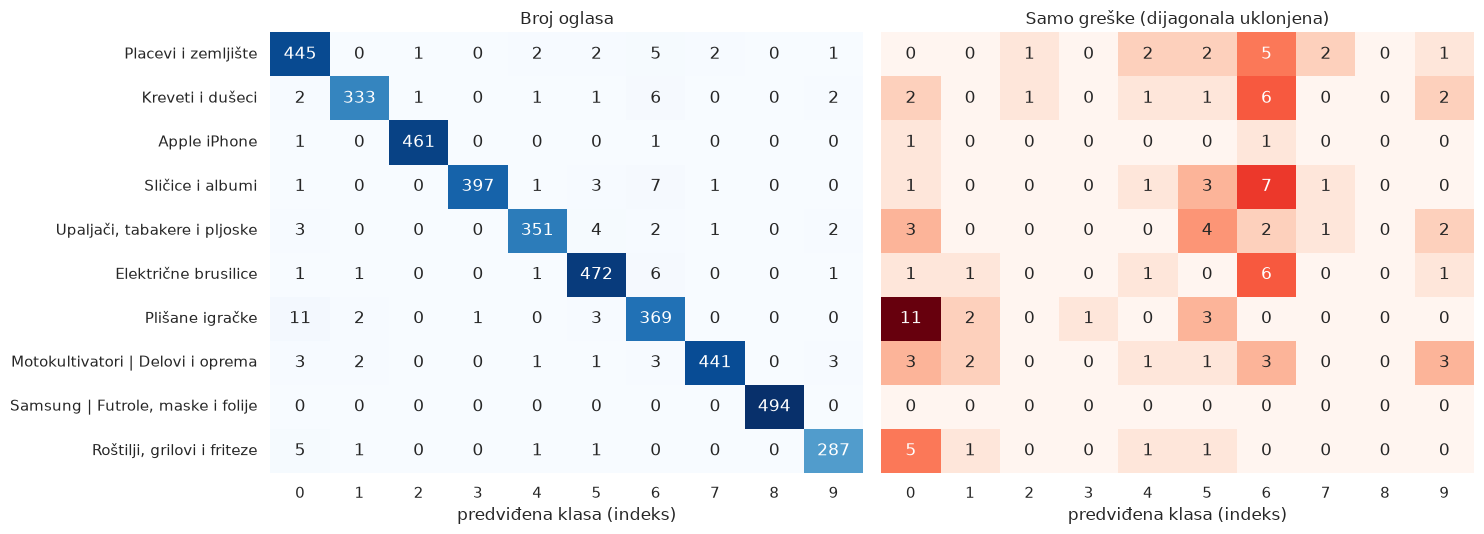

0                  Placevi i zemljište
1                     Kreveti i dušeci
2                         Apple iPhone
3                     Sličice i albumi
4         Upaljači, tabakere i pljoske
5                 Električne brusilice
6                      Plišane igračke
7    Motokultivatori | Delovi i oprema
8    Samsung | Futrole, maske i folije
9          Roštilji, grilovi i friteze


In [3]:
cm = confusion_matrix(y, pred)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=range(10), yticklabels=names, ax=ax[0])
ax[0].set_xlabel("predviđena klasa (indeks)"); ax[0].set_title("Broj oglasa")
off = cm.copy(); np.fill_diagonal(off, 0)
sns.heatmap(off, annot=True, fmt="d", cmap="Reds", cbar=False, xticklabels=range(10), yticklabels=False, ax=ax[1])
ax[1].set_xlabel("predviđena klasa (indeks)"); ax[1].set_title("Samo greške (dijagonala uklonjena)")
plt.tight_layout(); plt.show()
print(pd.Series(names).rename("indeks klase").to_string())

## 3.3 Provera preprilagođavanja (overfitting)

Preprilagođavanje znači da je model "naučio napamet" trening primere, pa na novim oglasima radi gore nego na treningu. Radim dve provere.

**Provera 1: razlika trening / validacija / test.** Ako su sva tri blizu, nema velikog problema; ako je test mnogo lošiji od treninga, model pamti.

In [4]:
rows = []
for name, (X, yy) in [("trening", (Xtr, ytr)), ("validacija", (Xva, yva)), ("test", (Xte, yte))]:
    l, a, _ = evaluate(model, X, yy)
    rows.append(dict(skup=name, accuracy=a, log_loss=l))
pd.DataFrame(rows).round(4)

,skup,accuracy,log_loss
0,trening,0.9913,0.0298
1,validacija,0.9735,0.1037
2,test,0.9757,0.0994


Tačnost na treningu je 99.13%, na validaciji 97.35% i na testu 97.57%, a log-loss 0.030, 0.104 i 0.099. Jaz između treninga i testa je oko 1.6 procentnih poena, veći nego kod MLP-a iz prvog projekta (oko 0.7). To je umereno preprilagođavanje: mreža i sa dropout-om 0.3 bolje zna trening nego nove oglase. Test nije lošiji od validacije, pa nema posledica po izmerenu tačnost, ali bi više podataka ili jača regularizacija verovatno pomogli.

## 3.4 Gde model greši: nepoznate reči

Rečnik ima samo reči koje su se u treningu pojavile bar `min_count` puta, a sve ostalo je `UNK`. Transformer za `UNK` reč ne zna ništa. Proveravam da li je tu uzrok grešaka, tako što poredim tačnost na naslovima koji sadrže bar jednu nepoznatu reč i na ostalima.

In [ ]:
has_unk = (Xte == 1).any(dim=1).numpy()     # 1 = UNK
ok = pred == y
print(f"naslova sa bar jednom nepoznatom rečju: {has_unk.mean():.3f}")
print(f"tačnost sa nepoznatom rečju : {ok[has_unk].mean():.4f}  (n={has_unk.sum()})")
print(f"tačnost bez nepoznatih reči : {ok[~has_unk].mean():.4f}  (n={(~has_unk).sum()})")
print(f"udeo grešaka koje imaju nepoznatu reč: {has_unk[~ok].mean():.3f}")x``

naslova sa bar jednom nepoznatom rečju: 0.550
tačnost sa nepoznatom rečju : 0.9615  (n=2284)
tačnost bez nepoznatih reči : 0.9930  (n=1867)
udeo grešaka koje imaju nepoznatu reč: 0.871
